# MSCA681 Tutorial 6: K nearest neigbors classifer (KNN)

* `kNN` involves taking the entire training dataset and storing it. Then, at prediction time, the k-closest examples in the training dataset are located for each new example for which we want to predict. The mode (most common value) class label from the k neighbors is then assigned to the new example.

* The k nearest Neighbors Classifier is available in the scikit-learn Python machine learning library via the `KNeighborsClassifier` class.

* The class allows you to specify the size of the k used when making a prediction via the “n_neighbors” argument, which defaults to 5.0.

* Another important hyperparameter is the “weights” argument that controls whether neighbors contribute to the prediction in a ‘uniform‘ manner or inverse to the distance (‘distance‘) from the example. 

## Data preparation

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Read the csv file
listings_df = pd.read_csv("listings_with_amenities.csv")
print(listings_df.shape)
# Display the first few rows of the DataFrame
listings_df.head()

(3585, 140)


,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,...,amenity_Other_pets,amenity_Washer___Dryer,amenity_Smoking_Allowed,amenity_Suitable_for_Events,amenity_Wheelchair_Accessible,amenity_Elevator_in_Building,amenity_Pool,amenity_Doorman,amenity_Paid_Parking_Off_Premises,amenity_Free_Parking_on_Street
0,12147973,https://www.airbnb.com/rooms/12147973,20160906204935,2016-09-07,Sunny Bungalow in the City,"Cozy, sunny, family home. Master bedroom high...",The house has an open and cozy feel at the sam...,"Cozy, sunny, family home. Master bedroom high...",none,"Roslindale is quiet, convenient and friendly. ...",...,0,0,0,0,0,0,0,0,0,0
1,3075044,https://www.airbnb.com/rooms/3075044,20160906204935,2016-09-07,Charming room in pet friendly apt,Charming and quiet room in a second floor 1910...,Small but cozy and quite room with a full size...,Charming and quiet room in a second floor 1910...,none,"The room is in Roslindale, a diverse and prima...",...,0,0,0,0,0,0,0,0,0,0
2,6976,https://www.airbnb.com/rooms/6976,20160906204935,2016-09-07,Mexican Folk Art Haven in Boston,"Come stay with a friendly, middle-aged guy in ...","Come stay with a friendly, middle-aged guy in ...","Come stay with a friendly, middle-aged guy in ...",none,The LOCATION: Roslindale is a safe and diverse...,...,0,0,0,0,0,0,0,0,0,0
3,1436513,https://www.airbnb.com/rooms/1436513,20160906204935,2016-09-07,Spacious Sunny Bedroom Suite in Historic Home,Come experience the comforts of home away from...,Most places you find in Boston are small howev...,Come experience the comforts of home away from...,none,Roslindale is a lovely little neighborhood loc...,...,0,0,0,0,0,0,0,0,0,0
4,7651065,https://www.airbnb.com/rooms/7651065,20160906204935,2016-09-07,Come Home to Boston,"My comfy, clean and relaxing home is one block...","Clean, attractive, private room, one block fro...","My comfy, clean and relaxing home is one block...",none,"I love the proximity to downtown, the neighbor...",...,0,0,0,0,0,0,0,0,0,0


Before moving forward, let's do some basic data cleaning.

In [3]:
# Replace the price column with a numeric version by removing $ and commas.
listings_df["price"] = listings_df["price"].replace({'\$': '', ',': ''}, regex=True).astype(float)
listings_df.loc[0:10, ["price", "name"]]

<>:2: SyntaxWarning: invalid escape sequence '\$'
<>:2: SyntaxWarning: invalid escape sequence '\$'
C:\Users\moeka\AppData\Local\Temp\ipykernel_21896\1152820713.py:2: SyntaxWarning: invalid escape sequence '\$'
  listings_df["price"] = listings_df["price"].replace({'\$': '', ',': ''}, regex=True).astype(float)


,price,name
0,250.0,Sunny Bungalow in the City
1,65.0,Charming room in pet friendly apt
2,65.0,Mexican Folk Art Haven in Boston
3,75.0,Spacious Sunny Bedroom Suite in Historic Home
4,79.0,Come Home to Boston
5,75.0,Private Bedroom + Great Coffee
6,100.0,New Lrg Studio apt 15 min to Boston
7,75.0,"""Tranquility"" on ""Top of the Hill"""
8,58.0,6 miles away from downtown Boston!
9,229.0,Perfect & Practical Boston Rental


Let's do some data clean-up

In [4]:
# We'll also clean up some outliers
listings_clean = listings_df.query('accommodates <= 10 & price <= 1000')
listings_clean = listings_clean.query('maximum_nights <= 2000')

# Filter by property type
property_types = ["Apartment", "House", "Condominium", "Townhouse", "Bed & Breakfast", "Loft"]
listings_clean = listings_clean[listings_clean["property_type"].isin(property_types)]
# filter to not include neighborhood_cleansed Leader District and Longwood Medical Area
listings_clean = listings_clean[~listings_clean["neighbourhood_cleansed"].isin(["Leather District", "Longwood Medical Area"])]    

# Find columns with sufficient fill (at most 25% missing values)
cols_keep = listings_clean.columns[listings_clean.isnull().mean() < 0.25]
# Keep only the columns with sufficient fill    
listings_clean = listings_clean[cols_keep]

# Let's one-hot encode our property types
listings_clean = pd.get_dummies(listings_clean, columns=["property_type"], drop_first = True, dtype = 'int')

# We're also going to filter to numeric columns for now-
# You can use one-hot encoding to handle categorical variables, but today we'll stick to this.
listings_clean = listings_clean.select_dtypes(include=[np.number, bool])

listings_clean.head(10)
print(cols_keep)

Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'name', 'summary',
       'description', 'experiences_offered', 'thumbnail_url', 'medium_url',
       ...
       'amenity_Other_pets', 'amenity_Washer___Dryer',
       'amenity_Smoking_Allowed', 'amenity_Suitable_for_Events',
       'amenity_Wheelchair_Accessible', 'amenity_Elevator_in_Building',
       'amenity_Pool', 'amenity_Doorman', 'amenity_Paid_Parking_Off_Premises',
       'amenity_Free_Parking_on_Street'],
      dtype='object', length=123)


## Missing values

It is important to check for missing values in our target variable and handle it properly.

In [5]:
# Check missing values in the original target variable
print("Missing target values:", listings_clean['review_scores_rating'].isnull().sum())

# Check percentage of missing target values
print("Percentage missing:", listings_clean['review_scores_rating'].isnull().mean() * 100)

Missing target values: 778
Percentage missing: 22.234924264075453


22% of the listings have missing review rating; it is better to remove these observations.

In [6]:
# Remove observations with missing target values
listings_clean = listings_clean.dropna(subset=['review_scores_rating']).copy()

# Verify that no missing target values remain
print("Missing target values:", listings_clean['review_scores_rating'].isnull().sum())

print("Remaining observations:", len(listings_clean))

Missing target values: 0
Remaining observations: 2721


# Defining the regression/classification problem

We're going to use the Boston Airbnb dataset, where each entry is a property listing, and aim to use the input variables available to us in order to do a classification of whether or not the listing has a high rating or not. 

Note here that we haven't specified exactly which variables in the dataset will be used to define each $x_i$. This choice of feature space is part of the modeling process, and we will experiment with it.

In [7]:
from sklearn.model_selection import train_test_split


# define the target variable
# target = listings_clean['price'] # For the prediction task, we will use price as the target variable.
# Create a new column based on the review_scores_rating > 90 using np.where()
listings_clean['high_rating'] = np.where(listings_clean['review_scores_rating'] > 90, 1, 0)
target = listings_clean['high_rating']  # Now we will predict high_rating instead of price.

# define the features
features = listings_clean.columns.drop(['id', 'scrape_id', 'host_id', 'latitude', 'longitude',
                                                 'availability_30','availability_60', 'availability_90', 'availability_365',
                                                 'host_total_listings_count','calculated_host_listings_count',
                                                 #'price', 
                                                 'review_scores_rating', 'high_rating',
                                                 'review_scores_accuracy',
                                                 'review_scores_cleanliness', 'review_scores_checkin', 
                                                 'review_scores_communication', 'review_scores_location',
                                                 'review_scores_value', 'number_of_reviews', 'reviews_per_month'])

## Training, Validation and Testing Splits

we want the model to generalise to unseen data.
To address this problem, we often split the dataset into three different chunks:

1. **Training data**: the data we build our models on.
1. **Validation data**: the data we tune hyperparameters on.
1. **Testing data**: the data we use to obtain a final estimate of performance.

The validation set is like an 'intermediate' estimate of performance. If we didn't use the validation set for this purpose, the only way of selecting the best model from a model class would be to look at its performance on the training set or the testing set.

`train_test_split` in `scikit-learn` provides an easy way of creating these data partitions. Let's start by just creating training/testing sets. We'll get to parameter tuning in a minute.

We will also stratify our split on this variable, meaning that the data is split to preserve the ratio of units with respect to the target variable in both the training and testing sets.

In [8]:
# Split the data into training and testing sets
# X_train, X_test, y_train, y_test = train_test_split(listings_clean_imputed[features], target, test_size=0.25, random_state=42)
# Split the data into training and testing with startifying 
X_train, X_test, y_train, y_test = train_test_split(listings_clean[features], target, test_size=0.25, random_state=42, stratify=target)

# Display the shapes of the training and testing sets
print("Training set shape:", X_train.shape, y_train.shape)
print("Testing set shape:", X_test.shape, y_test.shape)

Training set shape: (2040, 59) (2040,)
Testing set shape: (681, 59) (681,)


In [9]:
print(features)
print(X_train.columns)

Index(['host_listings_count', 'accommodates', 'bathrooms', 'bedrooms', 'beds',
       'price', 'guests_included', 'minimum_nights', 'maximum_nights',
       'amenity_TV', 'amenity_Wireless_Internet', 'amenity_Kitchen',
       'amenity_Free_Parking_on_Premises',
       'amenity_Pets_live_on_this_property', 'amenity_Dogs', 'amenity_Heating',
       'amenity_Family_Kid_Friendly', 'amenity_Washer', 'amenity_Dryer',
       'amenity_Smoke_Detector', 'amenity_Fire_Extinguisher',
       'amenity_Essentials', 'amenity_Shampoo',
       'amenity_Laptop_Friendly_Workspace', 'amenity_Internet',
       'amenity_Air_Conditioning', 'amenity_Pets_Allowed',
       'amenity_Carbon_Monoxide_Detector', 'amenity_Lock_on_Bedroom_Door',
       'amenity_Hangers', 'amenity_Hair_Dryer', 'amenity_Iron',
       'amenity_Cable_TV', 'amenity_First_Aid_Kit', 'amenity_Safety_Card',
       'amenity_other_49', 'amenity_other_50', 'amenity_Gym',
       'amenity_Breakfast', 'amenity_Indoor_Fireplace', 'amenity_Cats',
    

In [10]:
# Where are the missing values? (Training set)
missing_vals_train = X_train.isnull().sum()
# Display the columns with missing values
print("Training set:")
print(missing_vals_train.index[missing_vals_train>0])

# Where are the missing values? (Testing set)
missing_vals_test = X_test.isnull().sum()
# Display the columns with missing values
print("\nTesting set:")
print(missing_vals_test.index[missing_vals_test>0])

Training set:
Index(['bathrooms', 'bedrooms', 'beds'], dtype='object')

Testing set:
Index(['bathrooms'], dtype='object')


In [11]:
# Impute the missing values with the median of the column using sklearn's SimpleImputer 
from sklearn.impute import SimpleImputer

imp_median = SimpleImputer(missing_values=np.nan, strategy='median')
# Fit the imputer on the training set
imp_median.fit(X_train)
# Transform the training set
X_train_imputed = pd.DataFrame(imp_median.transform(X_train), columns=X_train.columns)

# Now, transform the testing set
X_test_imputed = pd.DataFrame(imp_median.transform(X_test), columns=X_test.columns)

Let's now observe our training data and do some basic pre-processing before training the models.

In [12]:
# summary of the training set
print("Training set summary:")
X_train_imputed.describe()

Training set summary:


,host_listings_count,accommodates,bathrooms,bedrooms,beds,price,guests_included,minimum_nights,maximum_nights,amenity_TV,...,amenity_Elevator_in_Building,amenity_Pool,amenity_Doorman,amenity_Paid_Parking_Off_Premises,amenity_Free_Parking_on_Street,property_type_Bed & Breakfast,property_type_Condominium,property_type_House,property_type_Loft,property_type_Townhouse
count,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,...,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000
mean,44.695588,3.028922,1.199510,1.246078,1.597059,165.115686,1.448039,3.167647,801.453431,0.772059,...,0.208824,0.033824,0.061765,0.000980,0.001961,0.008824,0.064706,0.169608,0.012745,0.019118
std,141.217959,1.708430,0.441141,0.744596,1.009222,106.764955,1.039318,10.089853,483.935130,0.419607,...,0.406568,0.180819,0.240787,0.031304,0.044248,0.093541,0.246066,0.375380,0.112200,0.136972
min,1.000000,1.000000,0.000000,0.000000,0.000000,11.000000,0.000000,1.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,2.000000,1.000000,1.000000,1.000000,85.000000,1.000000,1.000000,180.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2.000000,2.000000,1.000000,1.000000,1.000000,147.000000,1.000000,2.000000,1125.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,7.000000,4.000000,1.000000,1.000000,2.000000,212.500000,2.000000,3.000000,1125.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,749.000000,10.000000,4.000000,5.000000,16.000000,1000.000000,14.000000,300.000000,2000.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [13]:
# Normalize the data using MinMaxScaler
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
# Fit the scaler on the training data
scaler.fit(X_train)
# Transform the training and testing data
X_train_scaled = pd.DataFrame(scaler.transform(X_train_imputed), columns=X_train_imputed.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_imputed), columns=X_test_imputed.columns)

In [14]:
X_train_scaled.describe()

,host_listings_count,accommodates,bathrooms,bedrooms,beds,price,guests_included,minimum_nights,maximum_nights,amenity_TV,...,amenity_Elevator_in_Building,amenity_Pool,amenity_Doorman,amenity_Paid_Parking_Off_Premises,amenity_Free_Parking_on_Street,property_type_Bed & Breakfast,property_type_Condominium,property_type_House,property_type_Loft,property_type_Townhouse
count,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,...,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000,2040.000000
mean,0.058417,0.225436,0.299877,0.249216,0.099816,0.155830,0.103431,0.007250,0.400427,0.772059,...,0.208824,0.033824,0.061765,0.000980,0.001961,0.008824,0.064706,0.169608,0.012745,0.019118
std,0.188794,0.189826,0.110285,0.148919,0.063076,0.107952,0.074237,0.033745,0.242089,0.419607,...,0.406568,0.180819,0.240787,0.031304,0.044248,0.093541,0.246066,0.375380,0.112200,0.136972
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.111111,0.250000,0.200000,0.062500,0.074823,0.071429,0.000000,0.089545,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.001337,0.111111,0.250000,0.200000,0.062500,0.137513,0.071429,0.003344,0.562281,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.008021,0.333333,0.250000,0.200000,0.125000,0.203741,0.142857,0.006689,0.562281,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Fit and evaluate a KNN

We can fit and evaluate a K Neighbors Classifier model using repeated stratified k-fold cross-validation via the `RepeatedStratifiedKFold` class. We will use 5 folds and three repeats in the test harness.

KNN is sensitive to how data is split because it has no fixed parameters. It depends on distances to nearby points.
RepeatedStratifiedKFold improves reliability by:

1. Preserving class balance across folds (`Stratified`)
2. Repeating the process multiple times with different splits (`Repeated`)

In [27]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

# Define the model
knn = KNeighborsClassifier()
# define model evaluation method
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
# Evaluate the model using cross-validation
scores = cross_val_score(knn, X_train_scaled, y_train, scoring='roc_auc', cv=cv, n_jobs=-1)
# Print the mean and standard deviation of the scores``
print('Mean ROC AUC: %.3f (%.3f)' % (np.mean(scores), np.std(scores)))

Mean ROC AUC: 0.625 (0.026)


We may decide to use the K Neighbors Classifier as our final model and make predictions on new data.

This can be achieved by `fitting` the model pipeline on all available data and calling the `predict()` function passing in a new row of data.

Train ROC AUC: 0.816
Test ROC AUC: 0.622


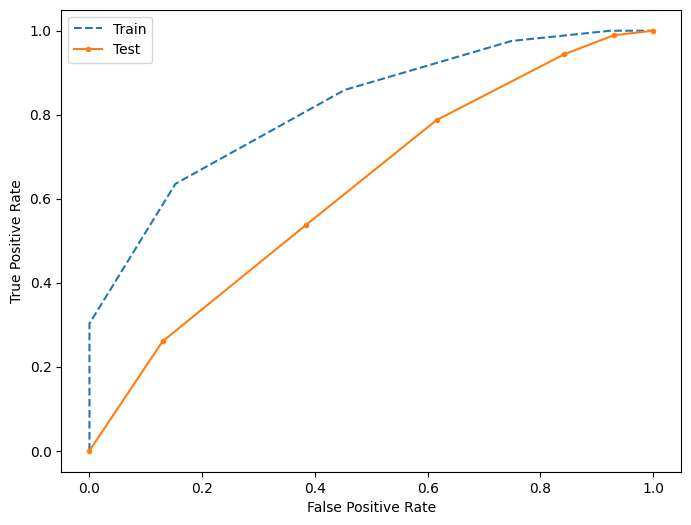

In [28]:
# fit model
knn.fit(X_train_scaled, y_train)
# Make predictions on the train set  
y_pred_train = knn.predict_proba(X_train_scaled)[:, 1]  # Get the probabilities for the positive class
# Make predictions on the test set
y_pred_test = knn.predict_proba(X_test_scaled)[:, 1]  # Get the probabilities for the positive class    

# Evaluate the model using ROC AUC
from sklearn.metrics import roc_auc_score   
roc_auc_train = roc_auc_score(y_train, y_pred_train)
roc_auc_test = roc_auc_score(y_test, y_pred_test)
print(f'Train ROC AUC: {roc_auc_train:.3f}')
print(f'Test ROC AUC: {roc_auc_test:.3f}')

# Plot the ROC curve for the training set
from sklearn.metrics import roc_curve   
fpr_train, tpr_train, _ = roc_curve(y_train, y_pred_train)
fpr_test, tpr_test, _ = roc_curve(y_test, y_pred_test)  
# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr_train, tpr_train, linestyle='--', label='Train')
plt.plot(fpr_test, tpr_test, marker='.', label='Test')
# axis labels
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
# show the legend
plt.legend()
# show the plot
plt.show()

In [29]:
# define a classification_evaluation function(model, X_train, y_train, X_test, y_test, threshold=0.5):
def classification_evaluation(model, X_train, y_train, X_test, y_test, threshold=0.5):
    from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, precision_score, recall_score, f1_score

    train_pred = model.predict_proba(X_train)[:, 1]
    test_pred = model.predict_proba(X_test)[:, 1]
    
    train_auc = roc_auc_score(y_train, train_pred)
    test_auc = roc_auc_score(y_test, test_pred)
    
    fpr_train, tpr_train, _ = roc_curve(y_train, train_pred)
    fpr_test, tpr_test, _ = roc_curve(y_test, test_pred)

    plt.figure(figsize=(8, 6))
    plt.plot(fpr_train, tpr_train, linestyle='--', label='Train')
    plt.plot(fpr_test, tpr_test, marker='.', label='Test')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend()
    plt.show()

    print("Training ROC AUC score:", train_auc)
    print("Testing ROC AUC score:", test_auc)
    print("Train Accuracy: %.3f" % accuracy_score(y_train, train_pred > threshold))
    print("Test Accuracy: %.3f" % accuracy_score(y_test, test_pred > threshold))
    # report precision, recall and f1 score for the training and testing sets
    print("Train Precision: %.3f" % precision_score(y_train, train_pred > threshold))   
    print("Test Precision: %.3f" % precision_score(y_test, test_pred > threshold))
    print("Train Recall: %.3f" % recall_score(y_train, train_pred > threshold)) 
    print("Test Recall: %.3f" % recall_score(y_test, test_pred > threshold))
    print("Train F1 Score: %.3f" % f1_score(y_train, train_pred > threshold))
    print("Test F1 Score: %.3f" % f1_score(y_test, test_pred > threshold))

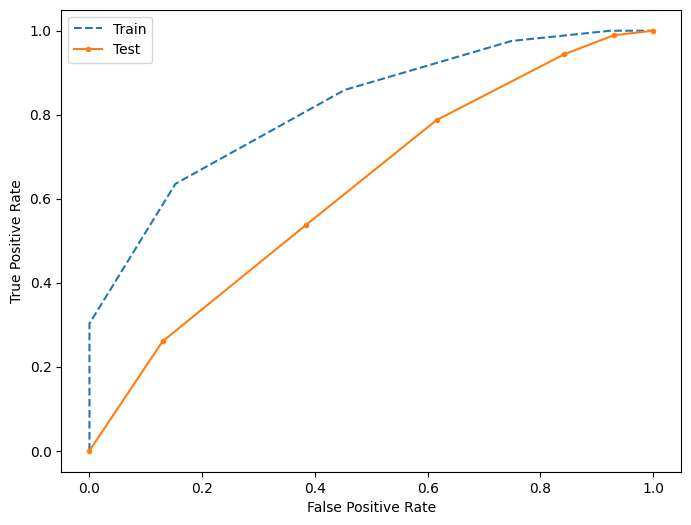

Training ROC AUC score: 0.816482582837723
Testing ROC AUC score: 0.6222321784149741
Train Accuracy: 0.760
Test Accuracy: 0.659
Train Precision: 0.803
Test Precision: 0.733
Train Recall: 0.859
Test Recall: 0.787
Train F1 Score: 0.830
Test F1 Score: 0.759


In [30]:
classification_evaluation(knn, X_train_scaled, y_train, X_test_scaled, y_test, threshold=0.5)

## Tuning a KNN classifier hyperparameteres


* The hyperparameters for the K Neighbors Classifier method must be configured for your specific dataset.
* Here we will try to tune `n_neighbors` and `weights`. What other hyper params you can tune for this model?


* It is important that the feature space is scaled prior to preparing and using the model.
* We can achieve this by using the `MinMaxScaler` to normalize the input features and use a Pipeline to first apply the scaling, then use the model.
* In this part we will also create a pipeline using the [`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) library. 



In [32]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier

numeric_cols = [
    'host_listings_count', 'accommodates', 'bathrooms',
    'bedrooms', 'beds', 'price', 'guests_included',
    'minimum_nights', 'maximum_nights'
]

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numeric_pipeline, numeric_cols)
    ],
    remainder='passthrough'
)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('knn', KNeighborsClassifier())
])

cv = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=3, random_state=42
)

param_grid = {
    'knn__n_neighbors': np.arange(1, 21, 2),
    'knn__weights': ['uniform', 'distance']
}

gs = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1
)

# Use the original data, before imputation and scaling
gs.fit(X_train, y_train)

print("Best Hyperparameters:", gs.best_params_)
print("Best ROC AUC Score:", gs.best_score_)

Best Hyperparameters: {'knn__n_neighbors': np.int64(19), 'knn__weights': 'distance'}
Best ROC AUC Score: 0.6480276534474166


Running the example will evaluate each combination of configurations using repeated cross-validation.

Note that we are grid searching the “n_neighbors” hyperparameter of the KNeighborsClassifier within the Pipeline where the model is named “knn” and, therefore, the n_neighbors parameter is accessed via knn->n_neighbors with a double underscore (__) separator, e.g. “knn__n_neighbors“.

Another metric that you might wish to explore is the distance metric used via the ‘metric‘ argument that defaults to ‘minkowski‘.

It might be interesting to compare results to ‘euclidean‘ distance and perhaps ‘cityblock‘ or `manhattan'.

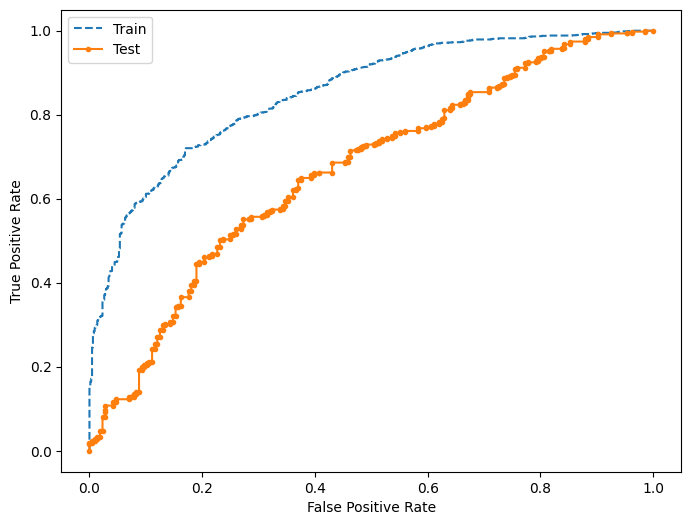

Training ROC AUC score: 0.8516392525579916
Testing ROC AUC score: 0.6665023894862605
Train Accuracy: 0.785
Test Accuracy: 0.680
Train Precision: 0.788
Test Precision: 0.721
Train Recall: 0.935
Test Recall: 0.867
Train F1 Score: 0.856
Test F1 Score: 0.787


In [33]:
knn_best = gs.best_estimator_
# Evaluate the best model on the training and testing sets
classification_evaluation(knn_best, X_train_scaled, y_train, X_test_scaled, y_test, threshold=0.5)

## What happenned?

When we used distance weighting, the model memorized training points. Training ROC AUC score became unrealistically high.

What should we do? (use different range of k, use uniform weights only, try PCA, ...)

Apply the concepts learned about Dimensionality Reduction (e.g. PCA) to this dataset and observe whether the model performance improves.

In [52]:
from sklearn.decomposition import PCA

# Keep enough components to explain 95% of total variance
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original features:", X_train_scaled.shape[1])
print("Reduced features:", X_train_pca.shape[1])

Original features: 59
Reduced features: 36


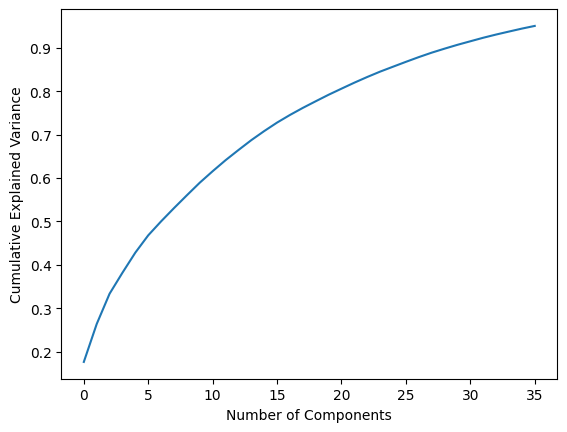

In [53]:
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.show()

In [56]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('pca', PCA(n_components=0.95)),
    ('knn', KNeighborsClassifier())
])

cv = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=3, random_state=42
)

param_grid = {
    'knn__n_neighbors': np.arange(1, 21, 2),
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan']
}

gs = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1
)

gs.fit(X_train, y_train)

print("Best Hyperparameters:", gs.best_params_)
print("Best ROC AUC Score:", gs.best_score_)

Best Hyperparameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': np.int64(19), 'knn__weights': 'distance'}
Best ROC AUC Score: 0.6438429007629041


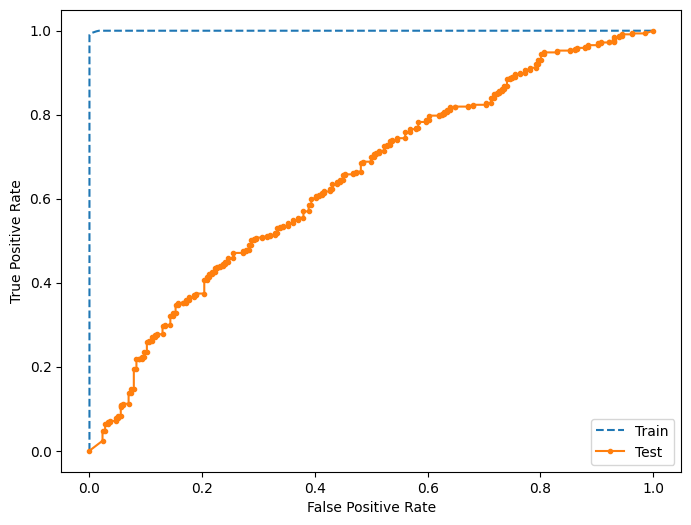

Training ROC AUC score: 0.9999401833711988
Testing ROC AUC score: 0.6441258462763839
Train Accuracy: 0.995
Test Accuracy: 0.668
Train Precision: 0.999
Test Precision: 0.717
Train Recall: 0.994
Test Recall: 0.849
Train F1 Score: 0.996
Test F1 Score: 0.778


In [57]:
knn_best = gs.best_estimator_
# Evaluate the best model on the training and testing sets
classification_evaluation(knn_best, X_train, y_train, X_test, y_test, threshold=0.5)

Try removing distance!